In [24]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter
import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, run_psy
from MLE_Predictive_Density import neg_loglik_student_mar, neg_loglik_student_marx, mar_studentt_pred_density, marx_studentt_pred_density

In [25]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility 
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol

### Import Nickel and detrend series with HP filter + linear trend of the volatility scaling

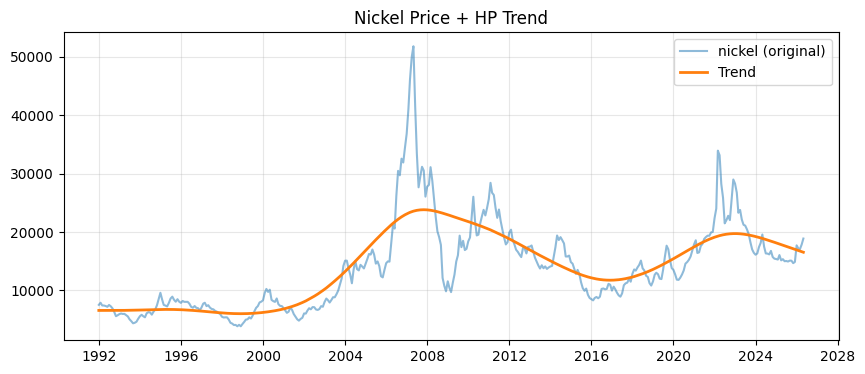

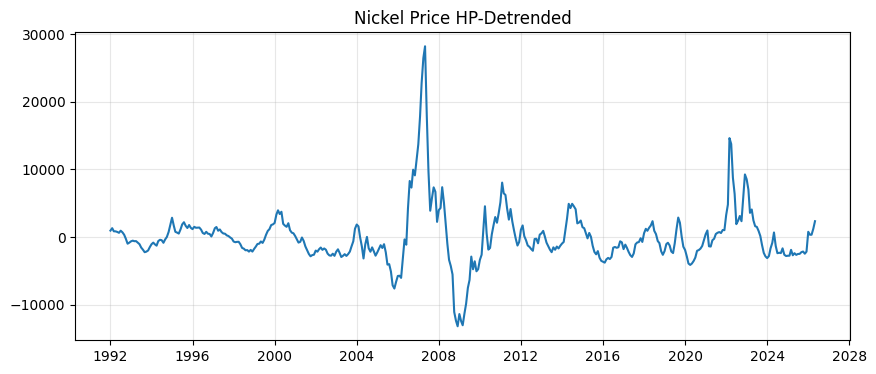

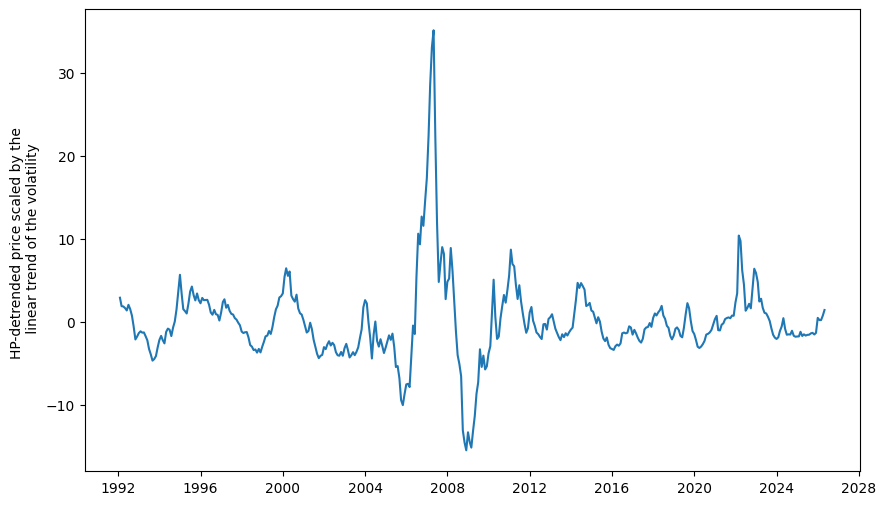

In [26]:
# -------------------------
# DATA
# -------------------------
df_nickel = pd.read_csv("PNICKUSDM.csv", parse_dates=["observation_date"])
df_nickel = df_nickel.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
cycle, trend = hpfilter(df_nickel["PNICKUSDM"], lamb=129600)

df_nickel["nickel_cycle"] = cycle
df_nickel["nickel_trend"] = trend


nickel_diff = (df_nickel["nickel_cycle"]).diff().dropna()
nickel_sigma = linear_vol_scale(nickel_diff)


df_nickel["nickel_scaled_cycle"]= df_nickel["nickel_cycle"]/nickel_sigma



# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["PNICKUSDM"], label="nickel (original)", alpha=0.5)
plt.plot(df_nickel.index, df_nickel["nickel_trend"], label="Trend", linewidth=2)
plt.title("Nickel Price + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_nickel.index, df_nickel["nickel_cycle"])
plt.title("Nickel Price HP-Detrended")
plt.grid(True, alpha=0.3)
plt.show()


# Plot scaled cycle 
plt.figure(figsize=(10,6))
plt.plot(df_nickel.index, df_nickel["nickel_scaled_cycle"])
plt.ylabel("HP-detrended price scaled by the \n linear trend of the volatility")
# Increase tick-label font size (axis scales)
#plt.tick_params(axis="both", labelsize=14)
plt.show()



In [27]:
# Get PSY For Nickel and save as pickle

T = len(df_nickel)
r0 = 0.01 + 1.8 / np.sqrt(T)
swindow0 = int(np.floor(r0 * T))
yr = 2
Tb = 12 * yr + swindow0 - 1

psy = run_psy(
    y=df_nickel["PNICKUSDM"].values,
    dates=df_nickel.index,
    IC=2,
    adflag=6,
    Tb = Tb,
    nboot=1999)


with open("psy_nickel.pkl", "wb") as f:
    pickle.dump(psy, f)

### Extract and Transform Data for Exogeous Variables

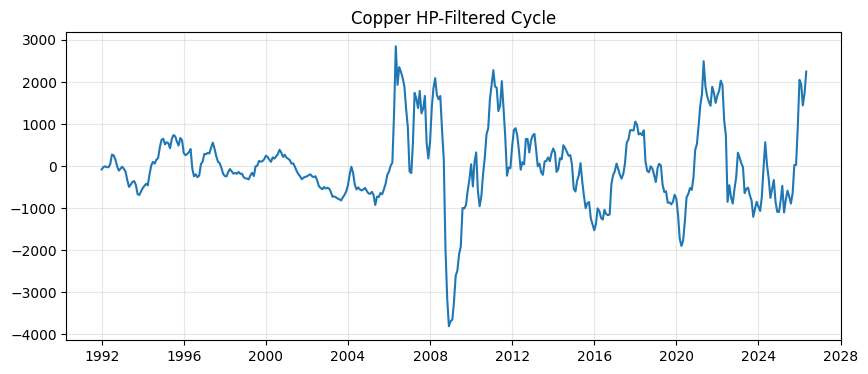

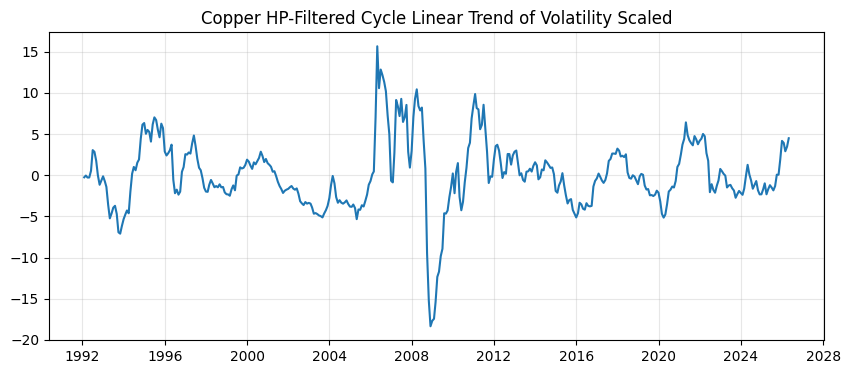

In [28]:
# -------------------------
# Copper
# -------------------------
df_copper = pd.read_csv("PCOPPUSDM.csv", parse_dates=["observation_date"])
df_copper = df_copper.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
copper_cycle, trend = hpfilter(df_copper, lamb=129600)

copper_diff = (copper_cycle).diff().dropna()
copper_sigma = linear_vol_scale(copper_diff)

copper= copper_cycle/copper_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(copper_cycle)
plt.title("Copper HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot scaled cycle 
plt.figure(figsize=(10,4))
plt.plot(copper)
plt.title("Copper HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

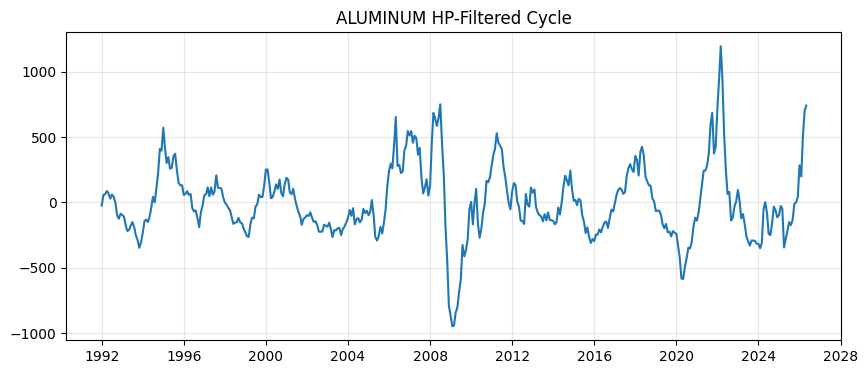

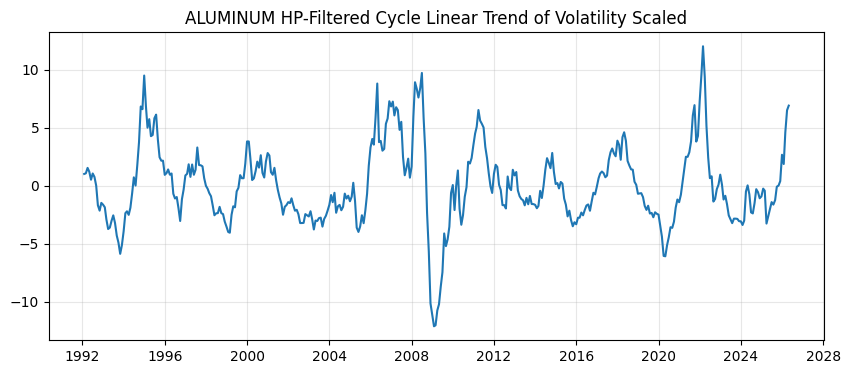

In [29]:
# -------------------------
# ALUMINUM
# -------------------------
df_al = pd.read_csv("PALUMUSDM.csv", parse_dates=["observation_date"])
df_al = df_al.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
al_cycle , trend = hpfilter(df_al["PALUMUSDM"], lamb=129600)

al_diff = (al_cycle).diff().dropna()
al_sigma = linear_vol_scale(al_diff)

al= al_cycle/al_sigma


# Plot cyclical component
plt.figure(figsize=(10,4))
plt.plot(al_cycle)
plt.title("ALUMINUM HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

# Plot scaled cycle 
plt.figure(figsize=(10,4))
plt.plot(al)
plt.title("ALUMINUM HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16048/3976212456.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


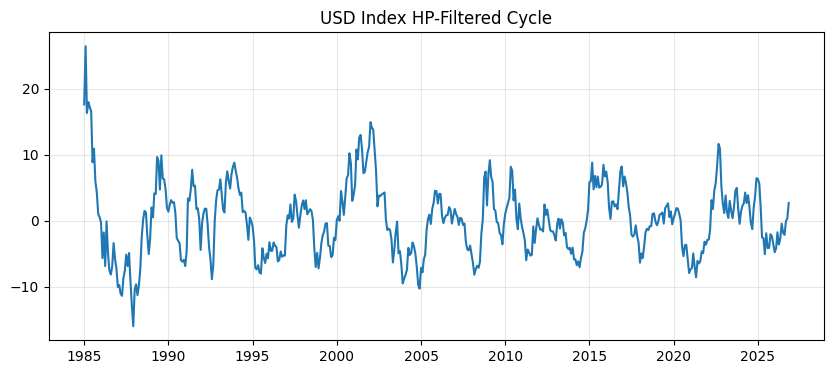

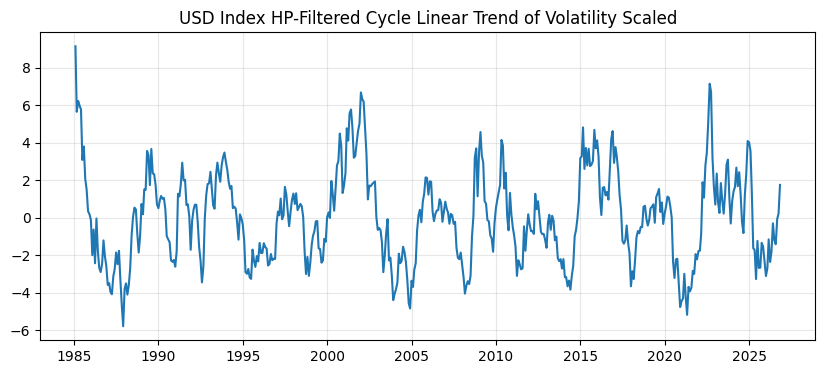

In [30]:
# -------------------------
# USD INDEX
# -------------------------
usd_ind_original = yf.download("DX-Y.NYB", start="1985-01-01", interval="1mo")["Close"]
usd_ind_original = usd_ind_original.dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
usd_ind_cycle, trend = hpfilter(usd_ind_original, lamb=129600)

usd_ind_diff = (usd_ind_cycle).diff().dropna()
usd_ind_sigma = linear_vol_scale(usd_ind_diff)

usd_ind= usd_ind_cycle/usd_ind_sigma


plt.figure(figsize=(10,4))
plt.plot(usd_ind_cycle)
plt.title("USD Index HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(usd_ind)
plt.title("USD Index HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

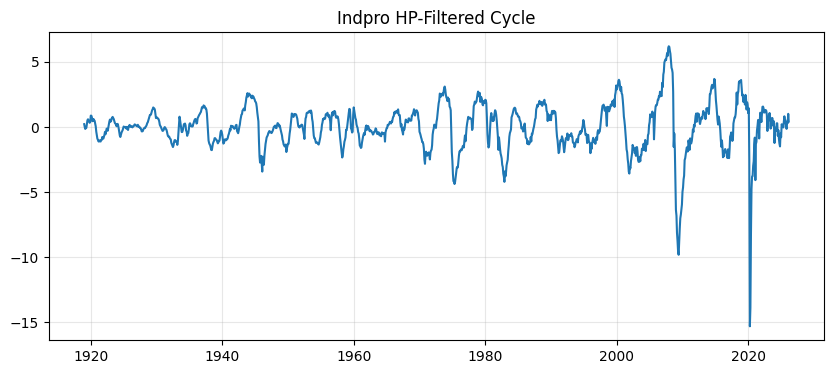

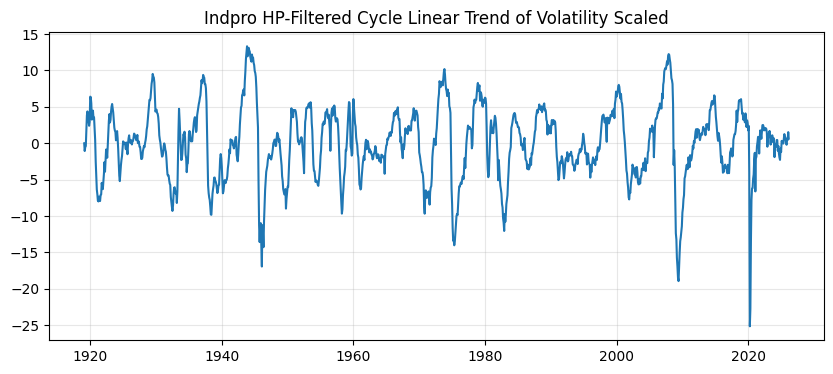

In [31]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16048/3959546231.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


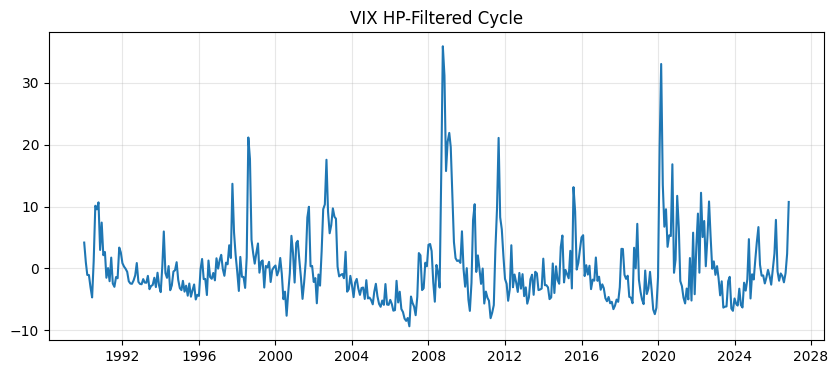

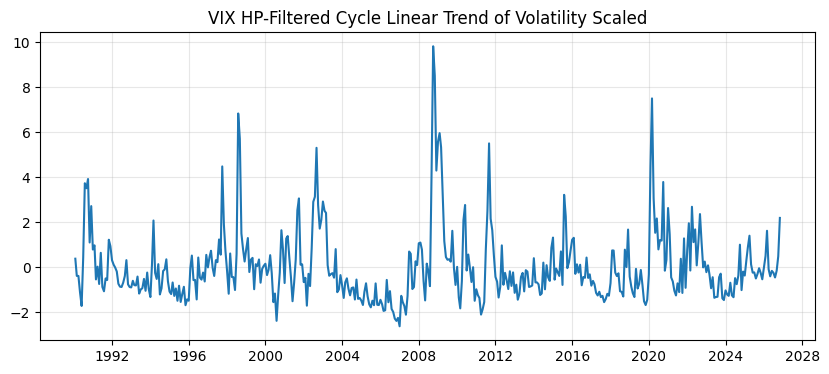

In [32]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

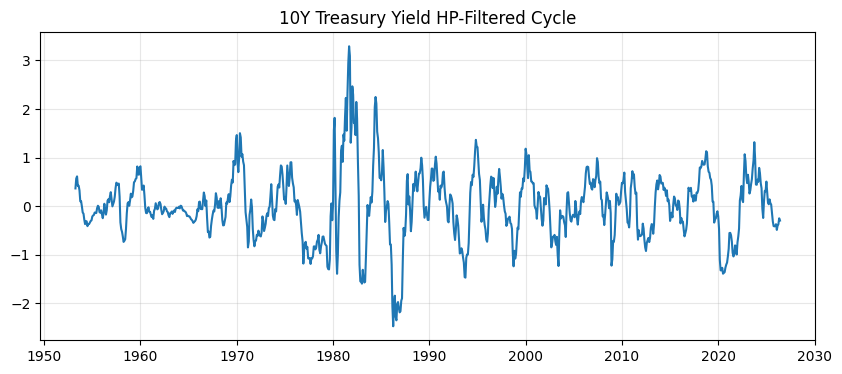

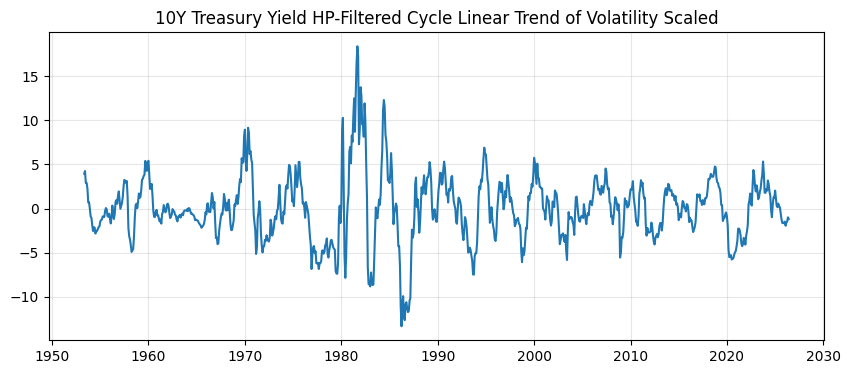

In [33]:
# -------------------------
# 10 Year Treasury Yield
# -------------------------
df_10y_treasury = pd.read_csv("GS10.csv", parse_dates=["observation_date"])
df_10y_treasury = df_10y_treasury.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
treasury_10y_cycle , trend = hpfilter(df_10y_treasury["GS10"], lamb=129600)

treasury_10y_diff = (treasury_10y_cycle).diff().dropna()
treasury_10y_sigma = linear_vol_scale(treasury_10y_diff)

treasury_10y= treasury_10y_cycle/treasury_10y_sigma


plt.figure(figsize=(10,4))
plt.plot(treasury_10y_cycle)
plt.title("10Y Treasury Yield HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(treasury_10y)
plt.title("10Y Treasury Yield HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

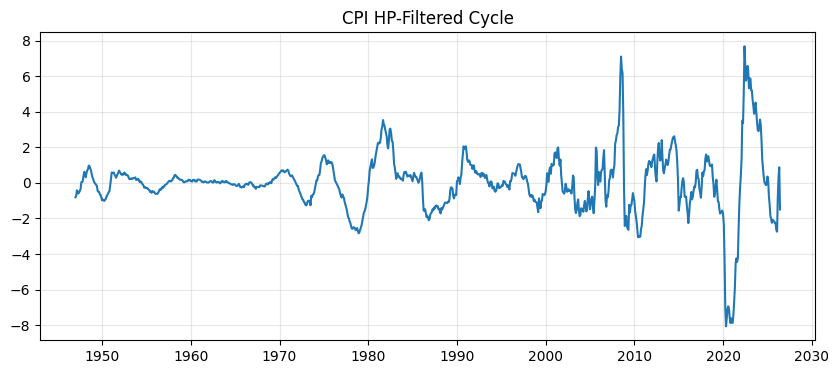

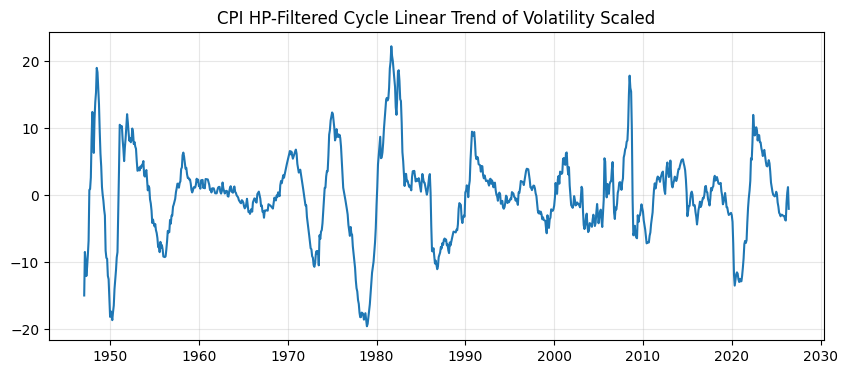

In [34]:
# -------------------------
# CPI
# -------------------------
df_cpi = pd.read_csv("CPIAUCSL.csv", parse_dates=["observation_date"])
df_cpi = df_cpi.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
cpi_cycle , trend = hpfilter(df_cpi["CPIAUCSL"], lamb=129600)


cpi_diff = (cpi_cycle).diff().dropna()
cpi_sigma = linear_vol_scale(cpi_diff)

cpi= cpi_cycle/cpi_sigma


plt.figure(figsize=(10,4))
plt.plot(cpi_cycle)
plt.title("CPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cpi)
plt.title("CPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

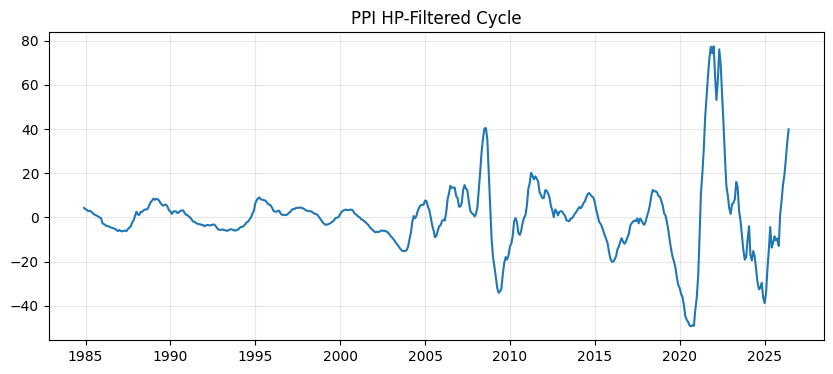

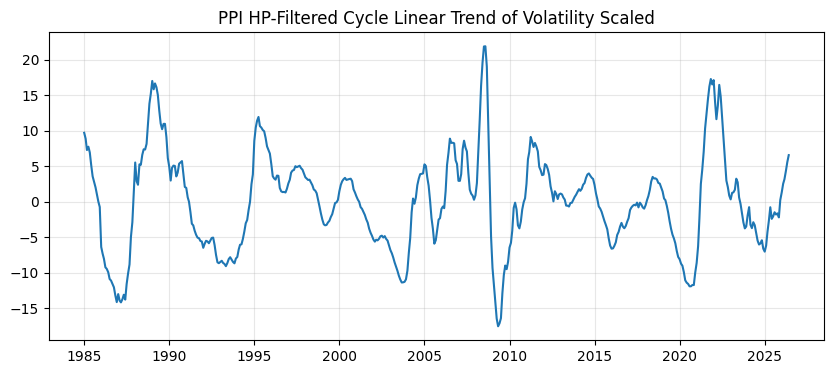

In [35]:
# -------------------------
# Producer Price Index by Industry: Primary Metal Manufacturing
# -------------------------
df_ppi = pd.read_csv("PCU331331.csv", parse_dates=["observation_date"])
df_ppi = df_ppi.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
ppi_cycle , trend = hpfilter(df_ppi["PCU331331"], lamb=129600)

ppi_diff = (ppi_cycle).diff().dropna()
ppi_sigma = linear_vol_scale(ppi_diff)

ppi= ppi_cycle/ppi_sigma


plt.figure(figsize=(10,4))
plt.plot(ppi_cycle)
plt.title("PPI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ppi)
plt.title("PPI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_16048/2615274562.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


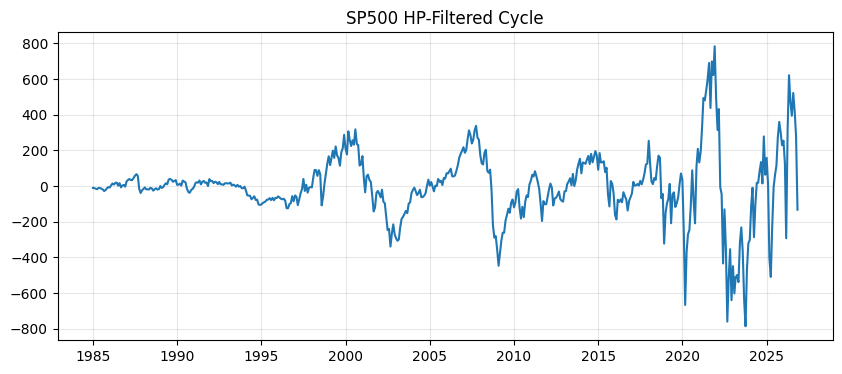

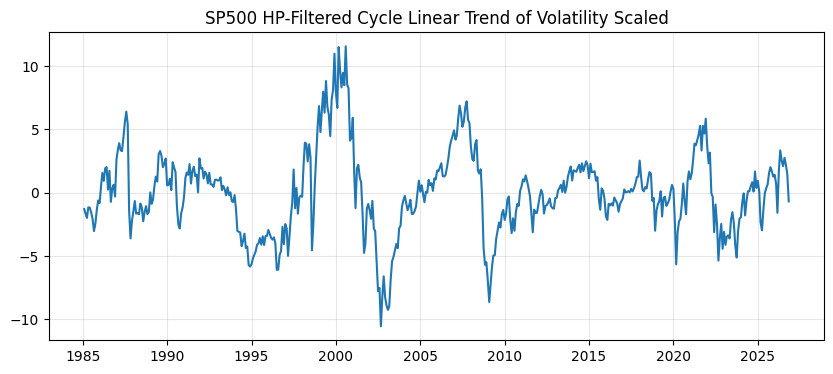

In [36]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter + linear trend of the volatility scaling
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

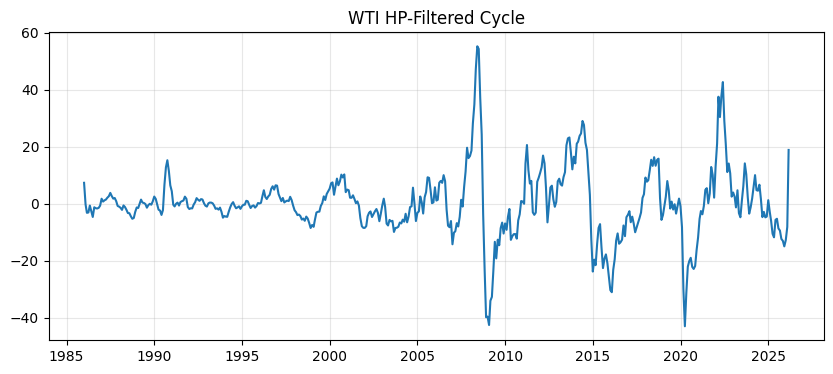

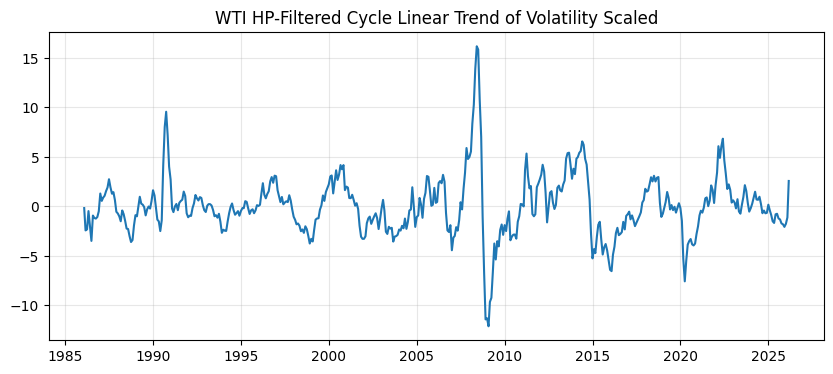

In [37]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter + linear trend of the volatility scaling
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma = linear_vol_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

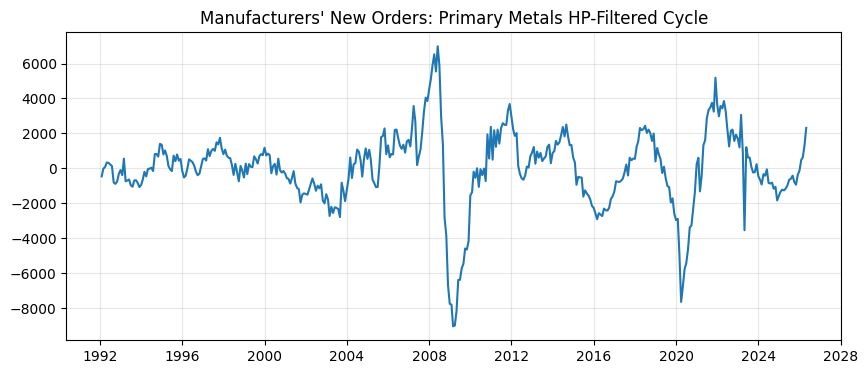

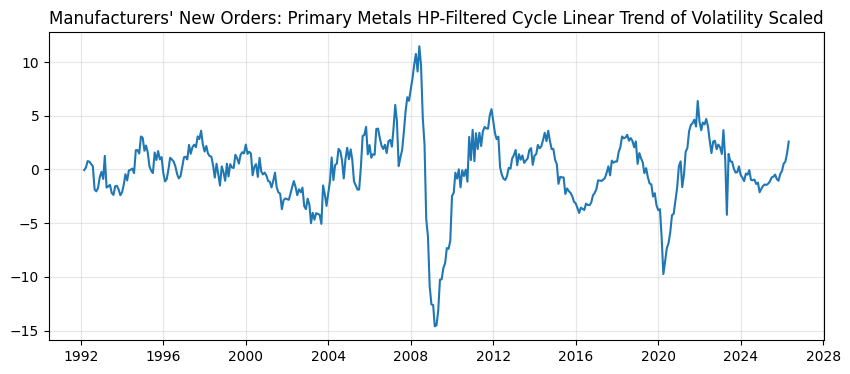

In [38]:
# -------------------------
# Manufacturers' New Orders: Primary Metals
# -------------------------
df_nom = pd.read_csv("A31SNO.csv", parse_dates=["observation_date"])
df_nom = df_nom.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
nom_cycle , trend = hpfilter(df_nom["A31SNO"], lamb=129600)

nom_diff = (nom_cycle).diff().dropna()
nom_sigma = linear_vol_scale(nom_diff)

nom = nom_cycle/nom_sigma


plt.figure(figsize=(10,4))
plt.plot(nom_cycle)
plt.title("Manufacturers' New Orders: Primary Metals HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(nom)
plt.title("Manufacturers' New Orders: Primary Metals HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

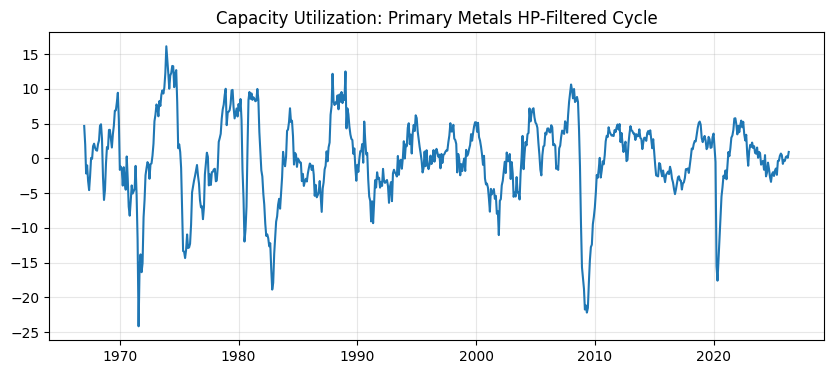

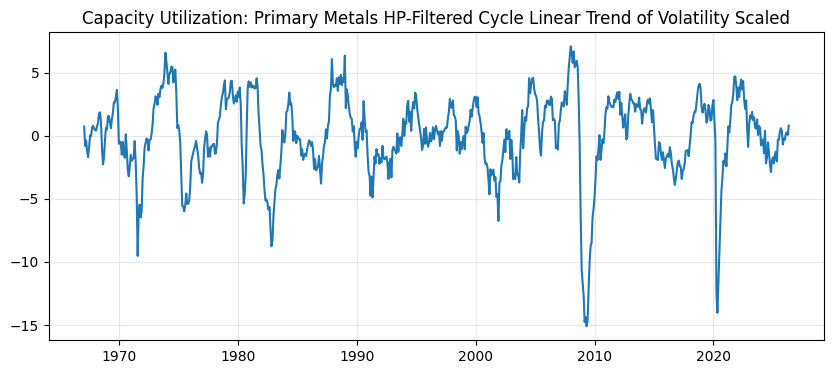

In [39]:
# -------------------------
# Capacity Utilization: Manufacturing: Durable Goods: Primary Metal
# -------------------------
df_cu = pd.read_csv("CAPUTLG331S.csv", parse_dates=["observation_date"])
df_cu = df_cu.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
cu_cycle , trend = hpfilter(df_cu["CAPUTLG331S"], lamb=129600)

cu_diff = (cu_cycle).diff().dropna()
cu_sigma = linear_vol_scale(cu_diff)

cu = cu_cycle/cu_sigma


plt.figure(figsize=(10,4))
plt.plot(cu_cycle)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(cu)
plt.title("Capacity Utilization: Primary Metals HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

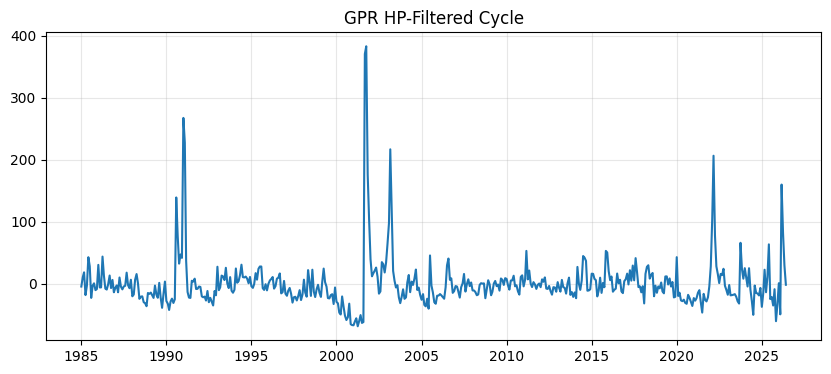

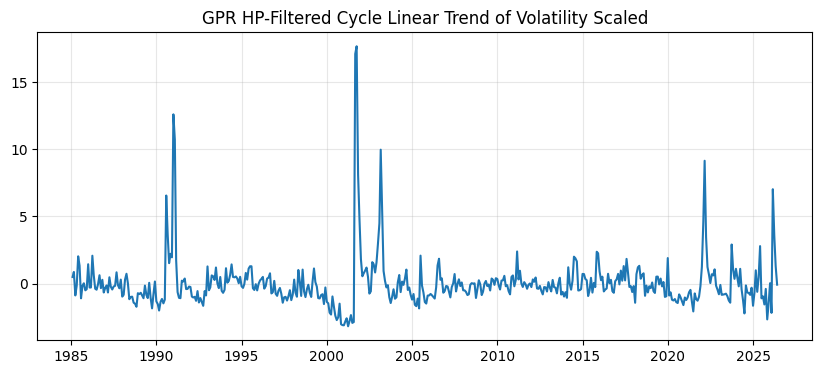

In [40]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma = linear_vol_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [41]:
# Data and Parameters 
df = pd.concat(
    [
        df_nickel["nickel_scaled_cycle"], copper, al, usd_ind, indpro, vix, treasury_10y, cpi, ppi, sp500, wti, nom, cu, gpr
    ],
    axis=1
).dropna()

df.columns = ["nickel_scaled_cycle", "copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]
df = df.sort_index()

start_date = "1992-03-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["nickel_scaled_cycle"].values
X = df[["copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]].values

var = ["copper", "al", "usd_ind", "indpro", "vix", "treasury_10y", "cpi", "ppi", "sp500", "wti", "nom", "cu", "gpr"]

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t0=202 # point to calculate predictive density

#Define Grid for all experiments
grid_min=-60
grid_max=60
ngrid=800
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)

prominence = 0.01
y_limits=(-25, 40)

Aligned sample: 408 monthly observations
Date range: 1992-03-01 to 2026-03-01


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -637.927783735405

Estimated parameters:
phi             =     0.6220 (0.0363)
psi             =     0.7460 (0.0375)
sigma           =     0.6554 (0.0478)
nu              =     1.8881 (0.2373)

Hessian condition number:
98.94340720810412

Eigenvalues of Hessian:
[1729.13586458  466.95649614  731.33454743   17.4760089 ]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -637.927784
AIC:            1283.855567
BIC:            1299.880980
R^2:            0.907523

Autocorrelation tests (standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 0.419247, p-value = 0.517313
    lag  5: statistic = 8.637721, p-value = 0.124416
    lag 10: statistic = 17.190257, p-value = 0.0702587
    lag 20: statistic = 29.704053, p-value = 0.0747931

Autocorrelation tests (squared standardized residuals):
  n       = 406
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 5

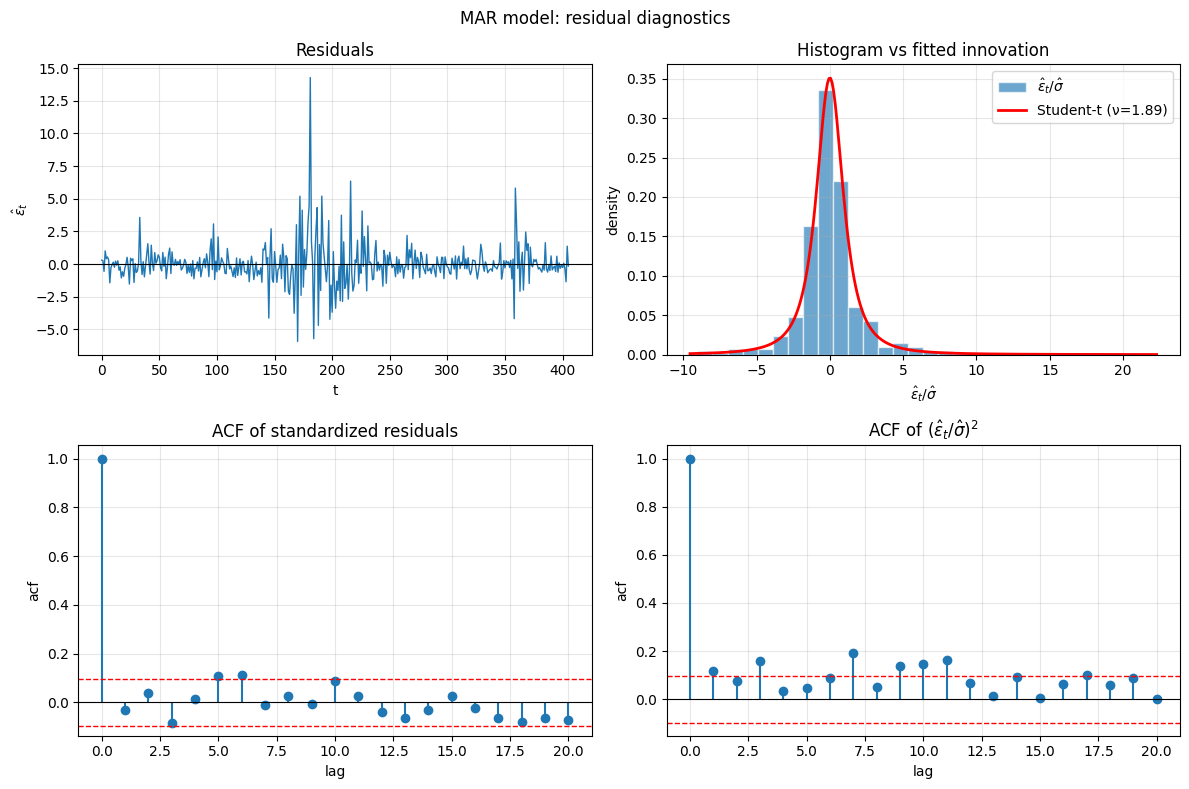

In [42]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

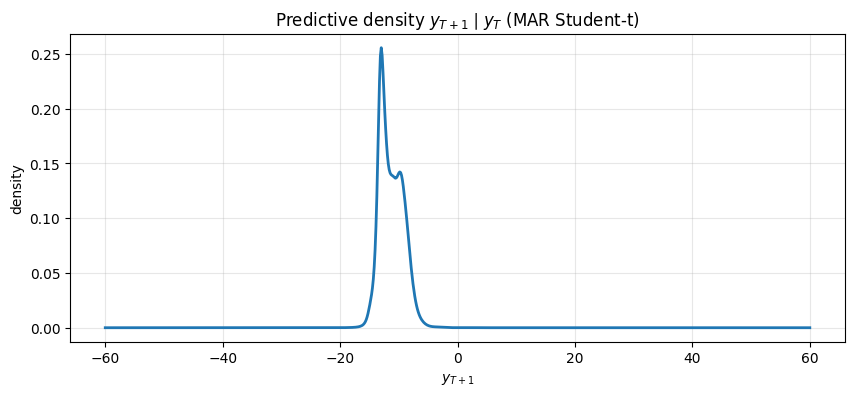

In [43]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

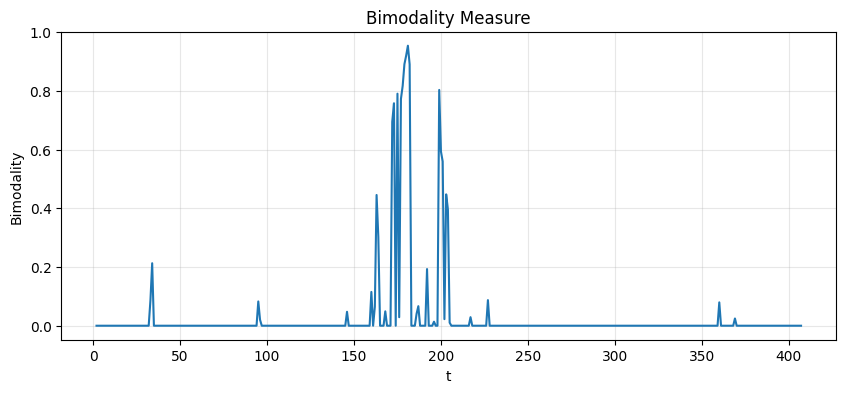

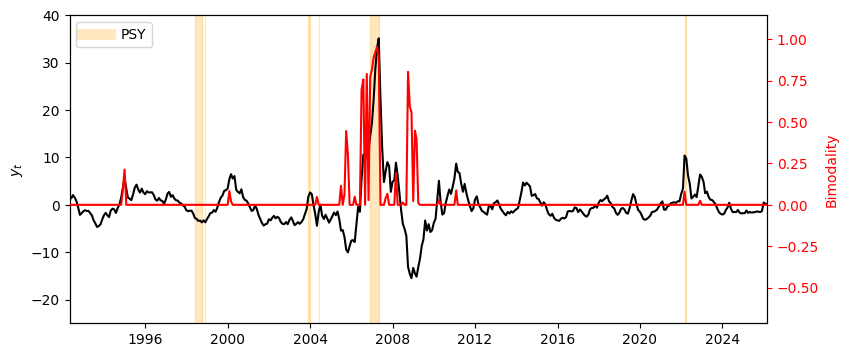

In [44]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -593.4885682807494

Estimated parameters:
phi             =     0.5203 (0.0267)
psi             =     0.6764 (0.0270)
beta_copper     =     0.1025 (0.0220)
beta_al         =     0.0917 (0.0333)
beta_usd_ind    =    -0.0095 (0.0223)
beta_indpro     =     0.0142 (0.0219)
beta_vix        =     0.0068 (0.0298)
beta_treasury_10y =    -0.0143 (0.0180)
beta_cpi        =     0.0460 (0.0176)
beta_ppi        =    -0.0430 (0.0116)
beta_sp500      =     0.0027 (0.0194)
beta_wti        =    -0.0414 (0.0276)
beta_nom        =    -0.0279 (0.0358)
beta_cu         =     0.0570 (0.0312)
beta_gpr        =    -0.0234 (0.0176)
sigma           =     0.5697 (0.0440)
nu              =     1.7967 (0.2288)

Hessian condition number:
3087.8309856961705

Eigenvalues of Hessian:
[5.80642252e+04 1.33317181e+04 1.13996664e+04 6.59226472e+03
 4.96260648e+03 3.70820483e+03 3.26125720e+03 2.42912772e+03
 2.04175401e+03 1.88042109e+01 1.69475571e+03 4.52080208e+02
 1.20559715e+

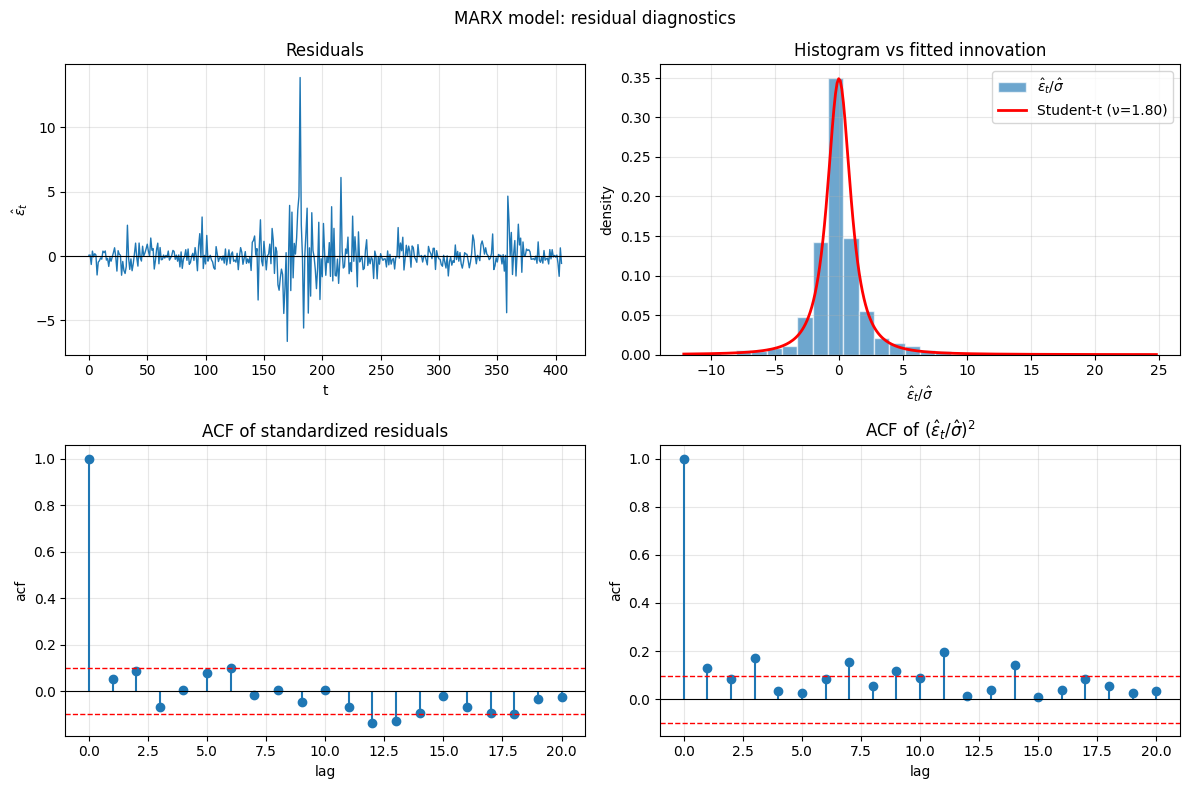

In [45]:
param_names = [ "phi", "psi", "beta_copper", "beta_al", "beta_usd_ind", "beta_indpro", "beta_vix", "beta_treasury_10y", "beta_cpi", "beta_ppi", "beta_sp500", "beta_wti", "beta_nom", "beta_cu", "beta_gpr", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### BIC Selection for Exogenous Regressors

In [47]:

from marx_bic_exhaustive import exhaustive_bic_marx

selection = exhaustive_bic_marx(
    y=y,
    X=X,
    names=var,
    n_starts=5,
    seed=42,
    min_nu=0.1,
    checkpoint="nickel_bic_checkpoint.pkl",
    save_every=25
)

display(selection["table"].head(20))


from marx_bic_exhaustive import refit_top_subsets

selection = refit_top_subsets(
    selection,
    y=y,
    X=X,
    names=var,
    top_n=10,
    n_starts=40
)

display(selection["table"].head(10))

best = selection["best"]

print("Selected regressors:", selection["selected_names"])
print("Log-likelihood:", best["loglik"])
print("AIC:", best["AIC"])
print("BIC:", best["BIC"])
print("Estimated nu:", best["theta"][-1])
print("Estimated parameters:", best["theta"])


New fits: 500 | recorded 500/8192
New fits: 1000 | recorded 1000/8192
New fits: 1500 | recorded 1500/8192
New fits: 2000 | recorded 2000/8192
New fits: 2500 | recorded 2500/8192
New fits: 3000 | recorded 3000/8192
New fits: 3500 | recorded 3500/8192
New fits: 4000 | recorded 4000/8192
New fits: 4500 | recorded 4500/8192
New fits: 5000 | recorded 5000/8192
New fits: 5500 | recorded 5500/8192
New fits: 6000 | recorded 6000/8192
New fits: 6500 | recorded 6500/8192
New fits: 7000 | recorded 7000/8192
New fits: 7500 | recorded 7500/8192
New fits: 8000 | recorded 8000/8192
Finished: 8192/8192 subsets; successes=8192, failures=0
Best subset: ['copper']
Best BIC=1243.293899; nu=1.9147


,regressors,ids,n_regressors,success,loglik,AIC,BIC,nu,n_converged
0,copper,"(0,)",1,True,-606.631066,1223.262133,1243.293899,1.914654,5
1,"copper, cpi","(0, 6)",2,True,-604.020917,1220.041833,1244.079952,1.871803,5
2,"copper, indpro","(0, 3)",2,True,-604.423192,1220.846384,1244.884503,1.932741,5
3,"copper, cpi, ppi","(0, 6, 7)",3,True,-601.744525,1217.489049,1245.533521,1.840394,5
4,"copper, indpro, ppi","(0, 3, 7)",3,True,-602.006367,1218.012735,1246.057207,1.931070,5
5,"copper, cu","(0, 11)",2,True,-605.134835,1222.269670,1246.307789,1.906191,5
6,"copper, ppi, cu","(0, 7, 11)",3,True,-602.132689,1218.265378,1246.309850,1.880814,5
7,"copper, al, ppi, cu","(0, 1, 7, 11)",4,True,-599.205920,1214.411841,1246.462666,1.861285,5
8,"copper, al, indpro, ppi","(0, 1, 3, 7)",4,True,-599.241394,1214.482787,1246.533613,1.905670,5
9,"copper, cpi, ppi, cu","(0, 6, 7, 11)",4,True,-599.421195,1214.842390,1246.893215,1.835487,5


,regressors,ids,n_regressors,success,loglik,AIC,BIC,nu,n_converged
0,copper,"(0,)",1,True,-606.631066,1223.262133,1243.293899,1.914654,40
1,"copper, cpi","(0, 6)",2,True,-604.020917,1220.041833,1244.079952,1.871803,40
2,"copper, indpro","(0, 3)",2,True,-604.423192,1220.846384,1244.884503,1.932741,5
3,"copper, cpi, ppi","(0, 6, 7)",3,True,-601.744525,1217.489049,1245.533521,1.840395,40
4,"copper, indpro, ppi","(0, 3, 7)",3,True,-602.006367,1218.012735,1246.057207,1.931071,40
5,"copper, cu","(0, 11)",2,True,-605.134835,1222.269670,1246.307789,1.906191,40
6,"copper, ppi, cu","(0, 7, 11)",3,True,-602.132689,1218.265378,1246.309850,1.880814,40
7,"copper, al, ppi, cu","(0, 1, 7, 11)",4,True,-599.205920,1214.411841,1246.462666,1.861285,40
8,"copper, al, indpro, ppi","(0, 1, 3, 7)",4,True,-599.241394,1214.482787,1246.533613,1.905671,40
9,"copper, cpi, ppi, cu","(0, 6, 7, 11)",4,True,-599.421195,1214.842390,1246.893215,1.835489,40


Selected regressors: ['copper']
Log-likelihood: -606.631066441919
AIC: 1223.262132883838
BIC: 1243.2938986818465
Estimated nu: 1.914653659612895
Estimated parameters: [0.54686578 0.67517083 0.12177324 0.61181245 1.91465366]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

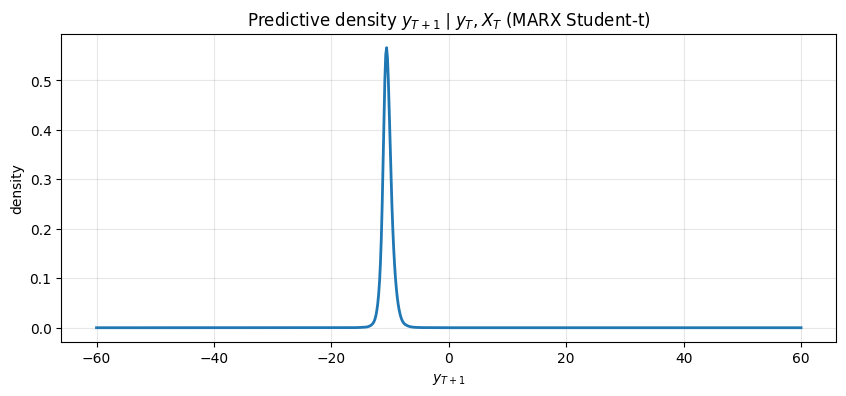

In [ ]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

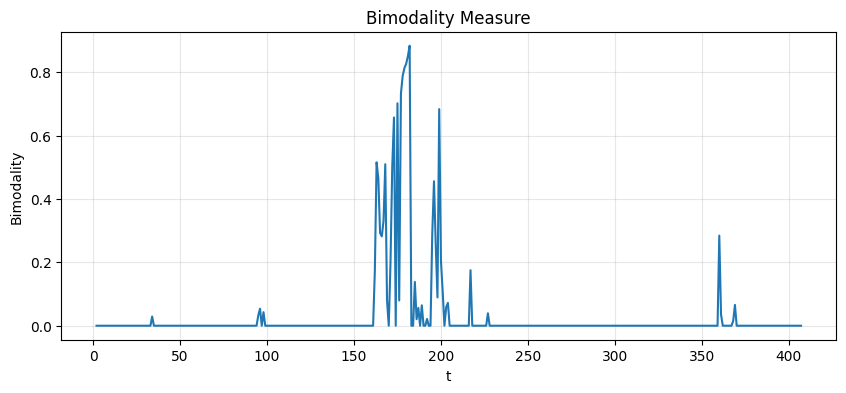

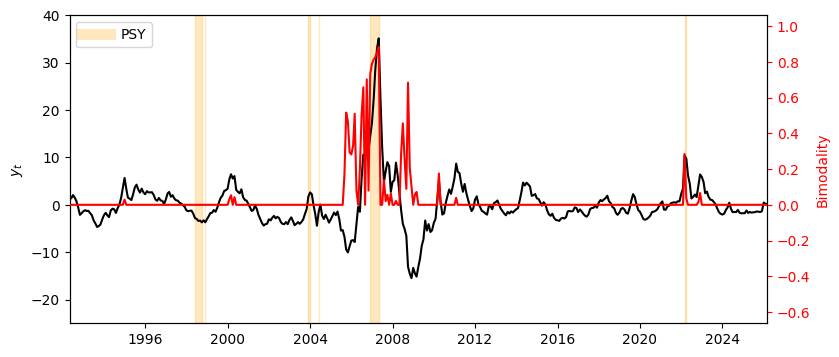

In [ ]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)
